# CSA0812 – Assignment 5
## B1 – Implement and Validate the Cleaning Pipeline

**Student:** Darshan A  
**Register:** 1973260011  
**Marks:** 7 | **K3 – Apply**

This notebook includes the written design comparison, exact Complete the Code exercise and full executable pipeline. Run the code cells from top to bottom in Google Colab.

## B1.1 – Validate the Implementation (2 Marks)

The implementation generates a raw sample station CSV containing the required quality problems: missing readings (`NA` and blank), negative and very large sensor values, an exact duplicate, inconsistent station-name whitespace/case, an alternate date format, Fahrenheit temperatures and invalid date/hour records.

The pipeline prints or saves the raw input, the cleaned rows and a cleaning log. The cleaned records use a canonical station name, ISO date, valid 0–23 hour, numeric pollutant readings and Celsius temperature. Invalid or unrecoverable records are rejected or left missing according to the cleaning policy.

**Required evidence:** capture the raw data preview, cleaned data preview and cleaning log after running the code below.

## B1.2 – Compare with the Design (1 Mark)

The implementation follows the Part A design by using CSV for source acquisition, validating numeric ranges, converting Fahrenheit readings to Celsius, standardising date and station formats, handling missing values, removing duplicate observations and retaining a cleaning log.

Implementation refinements include generating reproducible sample data and explicitly sorting by station/date/hour before forward filling. This keeps a previous reading within the same station and metric. Any difference between the original design and implementation should be stated using the observed data and cleaning log.

## B1.3 – Store and Query (2 Marks)

The cleaned dataset is loaded into SQLite using batched `executemany()` insertion. The database stores station metadata and readings separately. The program answers three typical board questions with SQL: average PM2.5 for Adyar in October, maximum PM10 by station, and count of readings with PM2.5 above 100 by station.

The SQL outputs should be checked against the cleaned dataset before being used for reporting.

## B1.4 – Visualise (2 Marks)

The program produces labelled charts for:
1. Daily PM2.5 trend at a selected station (line chart).
2. Mean PM2.5 comparison between stations (bar chart).
3. Temperature versus PM2.5 relationship (scatter plot).
4. Mean PM2.5 by hour (bar chart).

Each chart is followed by a short interpretation in the program output. The chart shows association or trends in the sample; it does not establish the cause of pollution.

## Complete the Code – TODO 1 and TODO 2

The provided complete-code exercise uses `csv.DictReader` with `io.StringIO`, skips blank / `NA` / negative PM2.5 values, converts valid readings to float, and applies min–max scaling rounded to three decimal places. An extra test value above 999 is included and rejected.

### B1 Complete the Code – Executed

In [1]:
"""B1 Complete the Code – TODO 1 and TODO 2 completed."""
import csv
import io

RAW = """station,date,pm25
Adyar,2026-10-01,48
Adyar,2026-10-02,NA
Adyar,2026-10-03,
Guindy,2026-10-01,95
Guindy,2026-10-02,-5
Guindy,2026-10-03,121
Adyar,2026-10-04,1500
"""


def load_clean(text):
    rows = []
    # TODO 1 completed
    reader = csv.DictReader(io.StringIO(text))
    for row in reader:
        value_text = (row.get("pm25") or "").strip()
        if value_text.upper() in ("", "NA"):
            continue
        try:
            value = float(value_text)
        except ValueError:
            continue
        if value < 0 or value > 999:
            continue
        rows.append((row["station"].strip(), row["date"].strip(), value))
    return rows


def min_max(values):
    # TODO 2 completed
    values = list(values)
    if not values:
        return []
    low, high = min(values), max(values)
    if high == low:
        return [0.0 for _ in values]
    return [round((value - low) / (high - low), 3) for value in values]


clean = load_clean(RAW)
print(clean)
print(min_max([pm for _, _, pm in clean]))


[('Adyar', '2026-10-01', 48.0), ('Guindy', '2026-10-01', 95.0), ('Guindy', '2026-10-03', 121.0)]
[0.0, 0.644, 1.0]


## Alternative Concept and Complexity Analysis

The program compares the `csv` module and line-by-line Python processing with pandas vectorised cleaning and normalisation at 1,000, 100,000 and 1,000,000 rows. Both approaches must inspect the input, so their overall time is O(n), but pandas typically uses more memory because the DataFrame stores columns and intermediate arrays in memory.

The sample run in the prepared environment measured:

| Rows | CSV loop (seconds) | pandas (seconds) | pandas DataFrame memory |
|---:|---:|---:|---:|
| 1,000 | 0.0011 | 0.0032 | 0.13 MiB |
| 100,000 | 0.1141 | 0.0469 | 13.38 MiB |
| 1,000,000 | 1.1171 | 0.2443 | 133.75 MiB |

These are environment-specific measurements; rerun in your Colab runtime and report its own measurements.

## Full B1 Cleaning Pipeline

Run the following code cell to generate sample data, clean it, save the SQLite database, query the data, create charts, benchmark CSV versus pandas, and verify the results.

B1 COMPLETE THE CODE
[('Adyar', '2026-10-01', 48.0), ('Guindy', '2026-10-01', 95.0), ('Guindy', '2026-10-03', 121.0)]
[0.0, 0.644, 1.0]
Z-score demonstration: [-1.324, 0.232, 1.092]
The value above 999 was correctly skipped.

Raw station file created: assignment5_b1_output/raw_station_readings.csv (483 rows)
BEFORE CLEANING – first 8 raw records:
station,date,hour,pm25,pm10,no2,temperature,temperature_unit
 adyar ,2026-10-01,0,26.4,49.8,11.1,22.9,C
 adyar ,2026-10-01,6,29.3,61.5,16.0,22.3,C
 adyar ,2026-10-01,12,28.1,52.9,15.7,28.0,C
 adyar ,2026-10-01,18,26.0,50.8,19.8,28.2,C
Adyar,2026-10-02,0,23.9,50.9,13.2,22.0,C
Adyar,2026-10-02,6,NA,66.0,13.8,22.6,C
Adyar,2026-10-02,12,35.1,68.5,15.2,26.4,C
Cleaning validation checks passed: unique keys and plausible sensor ranges.

AFTER CLEANING: 480 unique valid readings
Rejected/imputed/duplicate notes: 12
Examples:
- Adyar 2026-10-01 0: duplicate row skipped
- Adyar 2026-10-02 6: pm25 missing/invalid; imputed with 23.90
- Adyar | Invalid dat

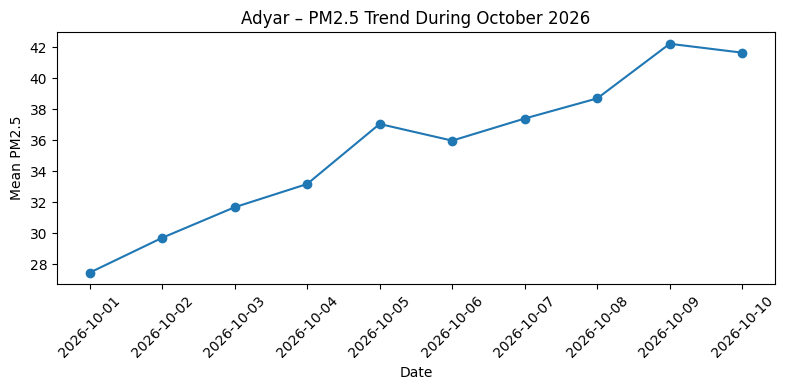


Chart 1 interpretation: The line chart shows how Adyar's mean PM2.5 changes by date. Peaks identify days that deserve closer investigation.


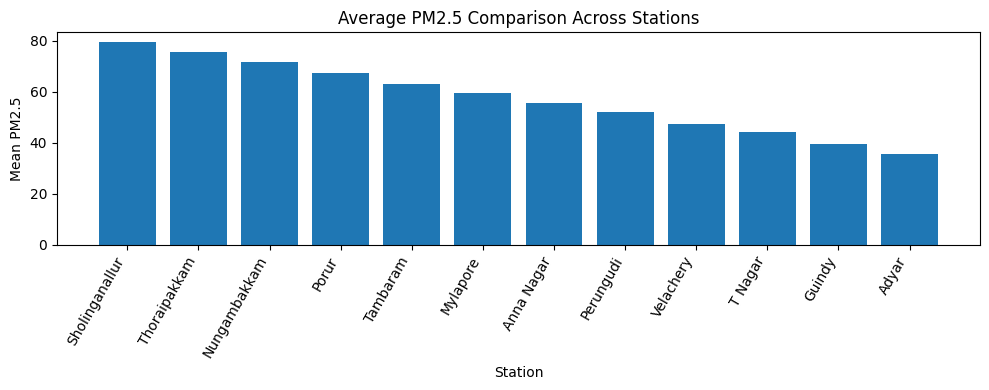

Chart 2 interpretation: The bar chart ranks stations by average PM2.5. Taller bars indicate stations with higher average particulate readings in the sample.


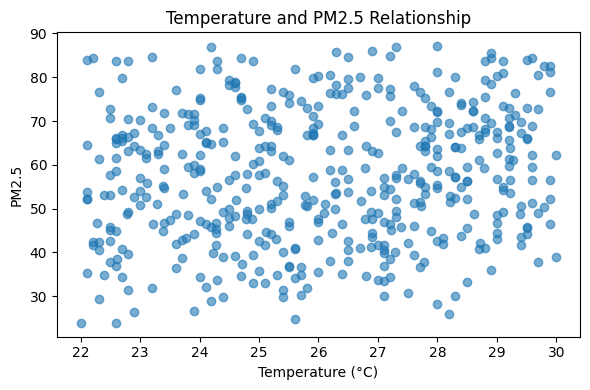

Chart 3 interpretation: The scatter plot checks whether higher temperatures occur alongside higher PM2.5 readings. A visible pattern suggests an association, not proof of causation.


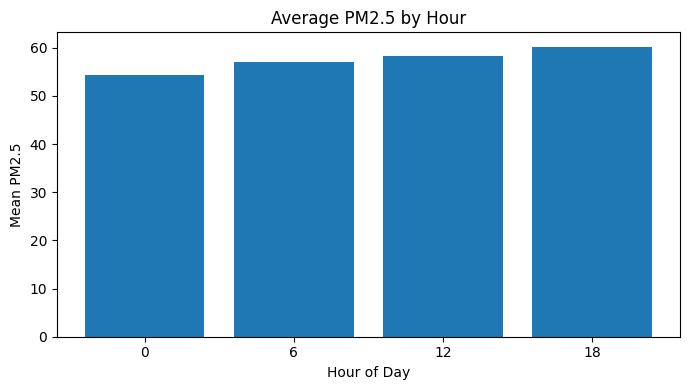

Chart 4 interpretation: The hourly bar chart identifies the highest-average hour in this sample: 18:00. This can guide time-specific monitoring.

Charts saved in: assignment5_b1_output/charts

CSV MODULE VS PANDAS BENCHMARK
Rows | csv loop seconds | pandas seconds | pandas DataFrame memory (MiB)
1,000 | 0.0025 | 0.0096 | 0.13
100,000 | 0.2183 | 0.0536 | 13.38
1,000,000 | 3.7095 | 0.4488 | 133.75

B1 completed: cleaned CSV, SQLite database, daily summary and four charts saved.


In [2]:
!pip -q install pandas matplotlib

"""
Assignment 5 – B1: Implement and Validate the Cleaning Pipeline
Darshan A | 1973260011 | CSA0812

Run in Google Colab or a local Python environment:
    python B1_cleaning_pipeline.py

Required libraries: pandas and matplotlib (plus Python standard library).
This script creates its own sample data, cleans it, stores it in SQLite,
runs SQL queries, writes a daily summary, creates four charts, and completes
the exact TODO 1/TODO 2 exercise from the assignment.
"""

from pathlib import Path
import csv
import io
import sqlite3
import statistics
import time
import random

import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path("assignment5_b1_output")
BASE_DIR.mkdir(exist_ok=True)

# ---------------------------------------------------------------------
# B1 COMPLETE THE CODE – exact supplied exercise with the added >999 test
# ---------------------------------------------------------------------

RAW = """station,date,pm25
Adyar,2026-10-01,48
Adyar,2026-10-02,NA
Adyar,2026-10-03,
Guindy,2026-10-01,95
Guindy,2026-10-02,-5
Guindy,2026-10-03,121
Adyar,2026-10-04,1500
"""


def load_clean(text):
    """Return (station, date, pm25) for valid, non-negative values <= 999."""
    rows = []
    reader = csv.DictReader(io.StringIO(text))
    for row in reader:
        raw_value = (row.get("pm25") or "").strip()
        if raw_value.upper() in ("", "NA"):
            continue
        try:
            value = float(raw_value)
        except ValueError:
            continue
        if value < 0 or value > 999:
            continue
        rows.append((row["station"].strip(), row["date"].strip(), value))
    return rows


def min_max(values):
    """Scale values to 0–1 and round to three decimals."""
    values = list(values)
    if not values:
        return []
    low, high = min(values), max(values)
    if high == low:
        return [0.0 for _ in values]
    return [round((value - low) / (high - low), 3) for value in values]


def z_score(values):
    """Standardise values using (value - mean) / population standard deviation."""
    values = list(values)
    if not values:
        return []
    mean_value = statistics.mean(values)
    deviation = statistics.pstdev(values)
    if deviation == 0:
        return [0.0 for _ in values]
    return [round((value - mean_value) / deviation, 3) for value in values]


def run_complete_code_demo():
    clean = load_clean(RAW)
    scaled = min_max([pm for _, _, pm in clean])
    z_scaled = z_score([pm for _, _, pm in clean])
    expected = [
        ("Adyar", "2026-10-01", 48.0),
        ("Guindy", "2026-10-01", 95.0),
        ("Guindy", "2026-10-03", 121.0),
    ]
    assert clean == expected
    assert scaled == [0.0, 0.644, 1.0]
    print("B1 COMPLETE THE CODE")
    print(clean)
    print(scaled)
    print("Z-score demonstration:", z_scaled)
    print("The value above 999 was correctly skipped.")


# ---------------------------------------------------------------------
# Create a small, realistic, deliberately messy station dataset
# ---------------------------------------------------------------------

STATIONS = [
    "Adyar", "Guindy", "T Nagar", "Velachery", "Perungudi", "Anna Nagar",
    "Mylapore", "Tambaram", "Porur", "Nungambakkam", "Thoraipakkam", "Sholinganallur"
]
FAHRENHEIT_STATIONS = {"Velachery", "Perungudi"}


def generate_raw_station_file(path):
    random.seed(42)
    rows = []
    start = pd.Timestamp("2026-10-01")
    for station_index, station in enumerate(STATIONS):
        for day_offset in range(10):
            day = (start + pd.Timedelta(days=day_offset)).strftime("%Y-%m-%d")
            for hour in (0, 6, 12, 18):
                pm25 = round(25 + station_index * 4 + day_offset * 1.7 + hour * 0.32
                             + random.uniform(-5, 5), 1)
                pm10 = round(pm25 * 1.8 + random.uniform(2, 12), 1)
                no2 = round(12 + station_index * 1.1 + hour * 0.4
                            + random.uniform(-2, 2), 1)
                temp_c = round(24 + 4 * (hour in (12, 18)) + random.uniform(-2, 2), 1)
                if station in FAHRENHEIT_STATIONS:
                    temperature = round(temp_c * 9 / 5 + 32, 1)
                    unit = "F"
                else:
                    temperature = temp_c
                    unit = "C"

                # Introduce examples of missing and impossible sensor readings.
                if station == "Adyar" and day_offset == 1 and hour == 6:
                    pm25 = "NA"
                if station == "Guindy" and day_offset == 2 and hour == 12:
                    pm10 = -12
                if station == "T Nagar" and day_offset == 3 and hour == 18:
                    no2 = 2500
                if station == "Mylapore" and day_offset == 4 and hour == 0:
                    temperature = ""
                if station == "Porur" and day_offset == 5 and hour == 6:
                    pm25 = ""
                if station == "Tambaram" and day_offset == 6 and hour == 12:
                    pm25 = 1500

                station_name = f" {station.lower()} " if station == "Adyar" and day_offset == 0 else station
                date_value = day
                if station == "Anna Nagar" and day_offset == 0 and hour == 0:
                    date_value = "01/10/2026"  # alternate but parseable date format

                rows.append([
                    station_name, date_value, hour, pm25, pm10, no2, temperature, unit
                ])

    # Add an exact duplicate row: it should be rejected by the duplicate rule.
    rows.append(rows[0].copy())

    # Add a row with an invalid date and another with an invalid hour.
    rows.append(["Adyar", "not-a-date", 8, 50, 80, 20, 25, "C"])
    rows.append(["Guindy", "2026-10-10", 25, 50, 80, 20, 25, "C"])

    fieldnames = [
        "station", "date", "hour", "pm25", "pm10", "no2",
        "temperature", "temperature_unit"
    ]
    with open(path, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(fieldnames)
        writer.writerows(rows)
    return len(rows)


# ---------------------------------------------------------------------
# Cleaning pipeline
# ---------------------------------------------------------------------

LIMITS = {
    "pm25": (0, 999),
    "pm10": (0, 2000),
    "no2": (0, 500),
    "temperature": (-40, 60),  # checked after Fahrenheit conversion
}


def parse_date(value):
    value = (value or "").strip()
    for fmt in ("%Y-%m-%d", "%d/%m/%Y"):
        try:
            return pd.to_datetime(value, format=fmt).strftime("%Y-%m-%d")
        except (ValueError, TypeError):
            pass
    raise ValueError(f"Invalid date: {value}")


def clean_station_csv(input_path, output_path):
    """Clean, standardise, deduplicate and impute rows; return clean rows and log."""
    with open(input_path, "r", newline="", encoding="utf-8") as file:
        raw_rows = list(csv.DictReader(file))

    # Valid sensor values are retained for median fallback.
    valid_values = {name: [] for name in LIMITS}
    for row in raw_rows:
        for name, (low, high) in LIMITS.items():
            raw = (row.get(name) or "").strip()
            if raw.upper() in ("", "NA", "N/A"):
                continue
            try:
                value = float(raw)
                if name == "temperature" and row.get("temperature_unit", "C").strip().upper() == "F":
                    value = (value - 32) * 5 / 9
                if low <= value <= high:
                    valid_values[name].append(value)
            except ValueError:
                continue

    medians = {
        name: statistics.median(values) if values else 0.0
        for name, values in valid_values.items()
    }

    cleaned = []
    errors = []
    seen = set()
    previous_by_station = {}

    # Sort by station/date/hour so forward-fill uses the prior reading of that sensor.
    def sort_key(row):
        station = (row.get("station") or "").strip().title()
        try:
            day = parse_date(row.get("date"))
        except ValueError:
            day = "9999-99-99"
        try:
            hour = int(row.get("hour", "0"))
        except ValueError:
            hour = 99
        return station, day, hour

    for original in sorted(raw_rows, key=sort_key):
        row = dict(original)
        station = (row.get("station") or "").strip().title()
        if not station:
            errors.append("Rejected row: station name is missing")
            continue

        try:
            day = parse_date(row.get("date"))
        except ValueError as error:
            errors.append(f"{station} | {error}")
            continue

        try:
            hour = int(row.get("hour", ""))
            if not 0 <= hour <= 23:
                raise ValueError("hour must be between 0 and 23")
        except ValueError as error:
            errors.append(f"{station} {day} | Invalid hour: {row.get('hour')} | {error}")
            continue

        key = (station, day, hour)
        if key in seen:
            errors.append(f"{station} {day} {hour}: duplicate row skipped")
            continue
        seen.add(key)

        values = {}
        row_is_usable = True
        for metric, (low, high) in LIMITS.items():
            raw = (row.get(metric) or "").strip()
            value = None
            if raw.upper() not in ("", "NA", "N/A"):
                try:
                    value = float(raw)
                except ValueError:
                    errors.append(f"{station} {day} {hour}: non-numeric {metric}={raw!r}")
                if value is not None and metric == "temperature":
                    unit = (row.get("temperature_unit") or "C").strip().upper()
                    if unit == "F":
                        value = (value - 32) * 5 / 9
                    elif unit != "C":
                        errors.append(f"{station} {day} {hour}: unknown temperature unit {unit!r}")
                        value = None
                if value is not None and not low <= value <= high:
                    errors.append(f"{station} {day} {hour}: impossible {metric}={value}; treated as missing")
                    value = None

            if value is None:
                previous = previous_by_station.get((station, metric))
                if previous is not None:
                    value = previous
                else:
                    value = medians[metric]
                errors.append(f"{station} {day} {hour}: {metric} missing/invalid; imputed with {value:.2f}")

            values[metric] = round(value, 2)
            previous_by_station[(station, metric)] = values[metric]

        if row_is_usable:
            cleaned.append({
                "station": station,
                "date": day,
                "hour": hour,
                "pm25": values["pm25"],
                "pm10": values["pm10"],
                "no2": values["no2"],
                "temperature_c": values["temperature"],
            })

    # Save cleaned CSV in a stable, standard format.
    fieldnames = ["station", "date", "hour", "pm25", "pm10", "no2", "temperature_c"]
    with open(output_path, "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(cleaned)

    return cleaned, errors


# ---------------------------------------------------------------------
# SQLite storage, queries and SQL daily summary
# ---------------------------------------------------------------------

def store_and_query(cleaned, database_path):
    if database_path.exists():
        database_path.unlink()

    con = sqlite3.connect(database_path)
    con.execute("PRAGMA foreign_keys = ON")
    con.executescript("""
        CREATE TABLE stations (
            station_id INTEGER PRIMARY KEY,
            station_name TEXT NOT NULL UNIQUE,
            source_temperature_unit TEXT NOT NULL
        );

        CREATE TABLE readings (
            reading_id INTEGER PRIMARY KEY,
            station_id INTEGER NOT NULL,
            day TEXT NOT NULL,
            hour INTEGER NOT NULL,
            pm25 REAL NOT NULL,
            pm10 REAL NOT NULL,
            no2 REAL NOT NULL,
            temperature_c REAL NOT NULL,
            UNIQUE(station_id, day, hour),
            FOREIGN KEY(station_id) REFERENCES stations(station_id)
        );
    """)

    station_names = sorted({row["station"] for row in cleaned})
    con.executemany(
        "INSERT INTO stations(station_name, source_temperature_unit) VALUES (?, ?)",
        [(name, "F" if name in FAHRENHEIT_STATIONS else "C") for name in station_names]
    )
    station_ids = dict(con.execute("SELECT station_name, station_id FROM stations").fetchall())

    con.executemany("""
        INSERT INTO readings(station_id, day, hour, pm25, pm10, no2, temperature_c)
        VALUES (?, ?, ?, ?, ?, ?, ?)
    """, [
        (
            station_ids[row["station"]], row["date"], row["hour"],
            row["pm25"], row["pm10"], row["no2"], row["temperature_c"]
        )
        for row in cleaned
    ])
    con.commit()

    print("\nTHREE SQL QUESTIONS FROM A1.3")
    print("1) Average PM2.5 at Adyar during October 2026:")
    result = con.execute("""
        SELECT AVG(r.pm25)
        FROM readings r JOIN stations s USING(station_id)
        WHERE s.station_name = ? AND r.day BETWEEN ? AND ?
    """, ("Adyar", "2026-10-01", "2026-10-31")).fetchone()[0]
    print(round(result, 2) if result is not None else None)

    print("2) Maximum PM10 reading by station:")
    for row in con.execute("""
        SELECT s.station_name, MAX(r.pm10)
        FROM readings r JOIN stations s USING(station_id)
        GROUP BY s.station_name ORDER BY s.station_name
    """):
        print(row)

    print("3) Number of hours with PM2.5 above 100 at each station:")
    for row in con.execute("""
        SELECT s.station_name,
               SUM(CASE WHEN r.pm25 > 100 THEN 1 ELSE 0 END)
        FROM stations s
        LEFT JOIN readings r USING(station_id)
        GROUP BY s.station_name ORDER BY s.station_name
    """):
        print(row)

    daily_summary = con.execute("""
        SELECT s.station_name, r.day,
               MIN(r.pm25), MAX(r.pm25), ROUND(AVG(r.pm25), 2), COUNT(r.pm25)
        FROM readings r JOIN stations s USING(station_id)
        GROUP BY s.station_name, r.day
        ORDER BY s.station_name, r.day
    """).fetchall()

    con.execute("""
        CREATE TABLE daily_summary (
            station_name TEXT, day TEXT, min_pm25 REAL, max_pm25 REAL,
            mean_pm25 REAL, valid_readings INTEGER,
            PRIMARY KEY(station_name, day)
        )
    """)
    con.executemany("INSERT INTO daily_summary VALUES (?, ?, ?, ?, ?, ?)", daily_summary)
    con.commit()

    summary_path = BASE_DIR / "daily_summary.csv"
    with open(summary_path, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["station", "date", "minimum", "maximum", "mean", "valid_readings"])
        writer.writerows(daily_summary)

    return con, daily_summary


# ---------------------------------------------------------------------
# Four charts selected in A3.1 and short interpretations
# ---------------------------------------------------------------------

def create_charts(con):
    chart_dir = BASE_DIR / "charts"
    chart_dir.mkdir(exist_ok=True)

    trend = pd.read_sql_query("""
        SELECT day, AVG(pm25) AS mean_pm25
        FROM readings r JOIN stations s USING(station_id)
        WHERE s.station_name = 'Adyar'
        GROUP BY day ORDER BY day
    """, con)
    plt.figure(figsize=(8, 4))
    plt.plot(trend["day"], trend["mean_pm25"], marker="o")
    plt.title("Adyar – PM2.5 Trend During October 2026")
    plt.xlabel("Date")
    plt.ylabel("Mean PM2.5")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(chart_dir / "01_pm25_monthly_trend.png")
    plt.show()
    plt.close()
    print("\nChart 1 interpretation: The line chart shows how Adyar's mean PM2.5 changes by date. Peaks identify days that deserve closer investigation.")

    stations = pd.read_sql_query("""
        SELECT s.station_name, AVG(r.pm25) AS mean_pm25
        FROM readings r JOIN stations s USING(station_id)
        GROUP BY s.station_name ORDER BY mean_pm25 DESC
    """, con)
    plt.figure(figsize=(10, 4))
    plt.bar(stations["station_name"], stations["mean_pm25"])
    plt.title("Average PM2.5 Comparison Across Stations")
    plt.xlabel("Station")
    plt.ylabel("Mean PM2.5")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.savefig(chart_dir / "02_station_comparison.png")
    plt.show()
    plt.close()
    print("Chart 2 interpretation: The bar chart ranks stations by average PM2.5. Taller bars indicate stations with higher average particulate readings in the sample.")

    relation = pd.read_sql_query(
        "SELECT temperature_c, pm25 FROM readings", con
    )
    plt.figure(figsize=(6, 4))
    plt.scatter(relation["temperature_c"], relation["pm25"], alpha=0.6)
    plt.title("Temperature and PM2.5 Relationship")
    plt.xlabel("Temperature (°C)")
    plt.ylabel("PM2.5")
    plt.tight_layout()
    plt.savefig(chart_dir / "03_temperature_vs_pm25.png")
    plt.show()
    plt.close()
    print("Chart 3 interpretation: The scatter plot checks whether higher temperatures occur alongside higher PM2.5 readings. A visible pattern suggests an association, not proof of causation.")

    hours = pd.read_sql_query("""
        SELECT hour, AVG(pm25) AS mean_pm25
        FROM readings GROUP BY hour ORDER BY hour
    """, con)
    plt.figure(figsize=(7, 4))
    plt.bar(hours["hour"].astype(str), hours["mean_pm25"])
    plt.title("Average PM2.5 by Hour")
    plt.xlabel("Hour of Day")
    plt.ylabel("Mean PM2.5")
    plt.tight_layout()
    plt.savefig(chart_dir / "04_worst_hours.png")
    plt.show()
    plt.close()
    worst = hours.loc[hours["mean_pm25"].idxmax()]
    print(f"Chart 4 interpretation: The hourly bar chart identifies the highest-average hour in this sample: {int(worst['hour']):02d}:00. This can guide time-specific monitoring.")

    return chart_dir


# ---------------------------------------------------------------------
# CSV module vs pandas vectorised cleaning timings for 1k/100k/1m rows
# ---------------------------------------------------------------------

def benchmark_csv_vs_pandas(sizes=(1_000, 100_000, 1_000_000)):
    print("\nCSV MODULE VS PANDAS BENCHMARK")
    print("Rows | csv loop seconds | pandas seconds | pandas DataFrame memory (MiB)")
    result_rows = []
    bench_dir = BASE_DIR / "benchmarks"
    bench_dir.mkdir(exist_ok=True)

    for size in sizes:
        path = bench_dir / f"benchmark_{size}.csv"
        with open(path, "w", newline="", encoding="utf-8") as file:
            writer = csv.writer(file)
            writer.writerow(["station", "date", "pm25"])
            for i in range(size):
                writer.writerow([f"Station{i % 12 + 1}", "2026-10-01", (i % 400) + 1])

        start = time.perf_counter()
        loop_values = []
        with open(path, "r", newline="", encoding="utf-8") as file:
            for row in csv.DictReader(file):
                value = float(row["pm25"])
                if 0 <= value <= 999:
                    loop_values.append(value)
        loop_seconds = time.perf_counter() - start

        start = time.perf_counter()
        frame = pd.read_csv(path)
        frame["pm25"] = pd.to_numeric(frame["pm25"], errors="coerce")
        frame = frame.loc[frame["pm25"].between(0, 999)].copy()
        low, high = frame["pm25"].min(), frame["pm25"].max()
        frame["pm25_scaled"] = 0.0 if high == low else (frame["pm25"] - low) / (high - low)
        pandas_seconds = time.perf_counter() - start
        memory_mib = frame.memory_usage(deep=True).sum() / (1024 * 1024)
        result_rows.append((size, loop_seconds, pandas_seconds, memory_mib))
        print(f"{size:,} | {loop_seconds:.4f} | {pandas_seconds:.4f} | {memory_mib:.2f}")

    return result_rows


def main():
    run_complete_code_demo()

    raw_path = BASE_DIR / "raw_station_readings.csv"
    clean_path = BASE_DIR / "cleaned_station_readings.csv"
    database_path = BASE_DIR / "air_quality.db"

    raw_count = generate_raw_station_file(raw_path)
    print(f"\nRaw station file created: {raw_path} ({raw_count} rows)")
    print("BEFORE CLEANING – first 8 raw records:")
    with open(raw_path, "r", encoding="utf-8") as file:
        for index, line in enumerate(file):
            if index == 8:
                break
            print(line.rstrip())

    cleaned, errors = clean_station_csv(raw_path, clean_path)
    unique_keys = {(row["station"], row["date"], row["hour"]) for row in cleaned}
    assert len(unique_keys) == len(cleaned)
    assert all(0 <= row["pm25"] <= 999 for row in cleaned)
    assert all(0 <= row["pm10"] <= 2000 for row in cleaned)
    assert all(0 <= row["no2"] <= 500 for row in cleaned)
    assert all(-40 <= row["temperature_c"] <= 60 for row in cleaned)
    print("Cleaning validation checks passed: unique keys and plausible sensor ranges.")
    print(f"\nAFTER CLEANING: {len(cleaned)} unique valid readings")
    print("Rejected/imputed/duplicate notes:", len(errors))
    print("Examples:")
    for message in errors[:12]:
        print("-", message)

    con, summary = store_and_query(cleaned, database_path)
    print(f"\nSQLite database created: {database_path}")
    print(f"Daily summary rows created: {len(summary)}")
    chart_dir = create_charts(con)
    con.close()

    print(f"\nCharts saved in: {chart_dir}")
    benchmark_csv_vs_pandas()

    print("\nB1 completed: cleaned CSV, SQLite database, daily summary and four charts saved.")


if __name__ == "__main__":
    main()


## Result and Interpretation

The run generates `assignment5_b1_output/` with the raw and cleaned CSV files, cleaning log, SQLite database, daily summary, chart images and benchmark CSV. Review the printed SQL answers and chart interpretations. Save screenshots of the before/after data, SQL results, charts and benchmark output.